LOADING DATA
File berhasil dibaca: ClassicMetal.csv

5 DATA PERTAMA:
                                               Track            Artist  \
0                                           3 Libras  A Perfect Circle   
1                              By And Down The River  A Perfect Circle   
2  Counting Bodies Like Sheep To The Rhythm Of Th...  A Perfect Circle   
3                                            Imagine  A Perfect Circle   
4                                             Judith  A Perfect Circle   

              Album  Year  Duration  Time_Signature  Danceability  Energy  \
0       Mer De Noms  2000    219640               3         0.518   0.744   
1  Eat The Elephant  2003    304906               3         0.231   0.640   
2           eMOTIVe  2004    336440               4         0.632   0.938   
3           eMOTIVe  2004    288000               4         0.537   0.495   
4       Mer De Noms  2000    247266               3         0.366   0.894   

   Key  Loudness  Mode 

,No,Analisis,Hasil Utama
0,1,Top Artist,Black Sabbath (13 lagu)
1,2,Artis Paling Energik,Lamb of God
2,3,Lagu Paling Energik,Bleed (Meshuggah)
3,4,Key Paling Populer,Key 2 (D)
4,5,Tahun Rilis Terbanyak,Tahun 1984 (46 lagu)
5,6,Korelasi Energy vs Loudness,r = 0.595 (p = 3.25e-89)
6,7,Korelasi Danceability vs Energy,r = -0.064 (p = 5.26e-02)


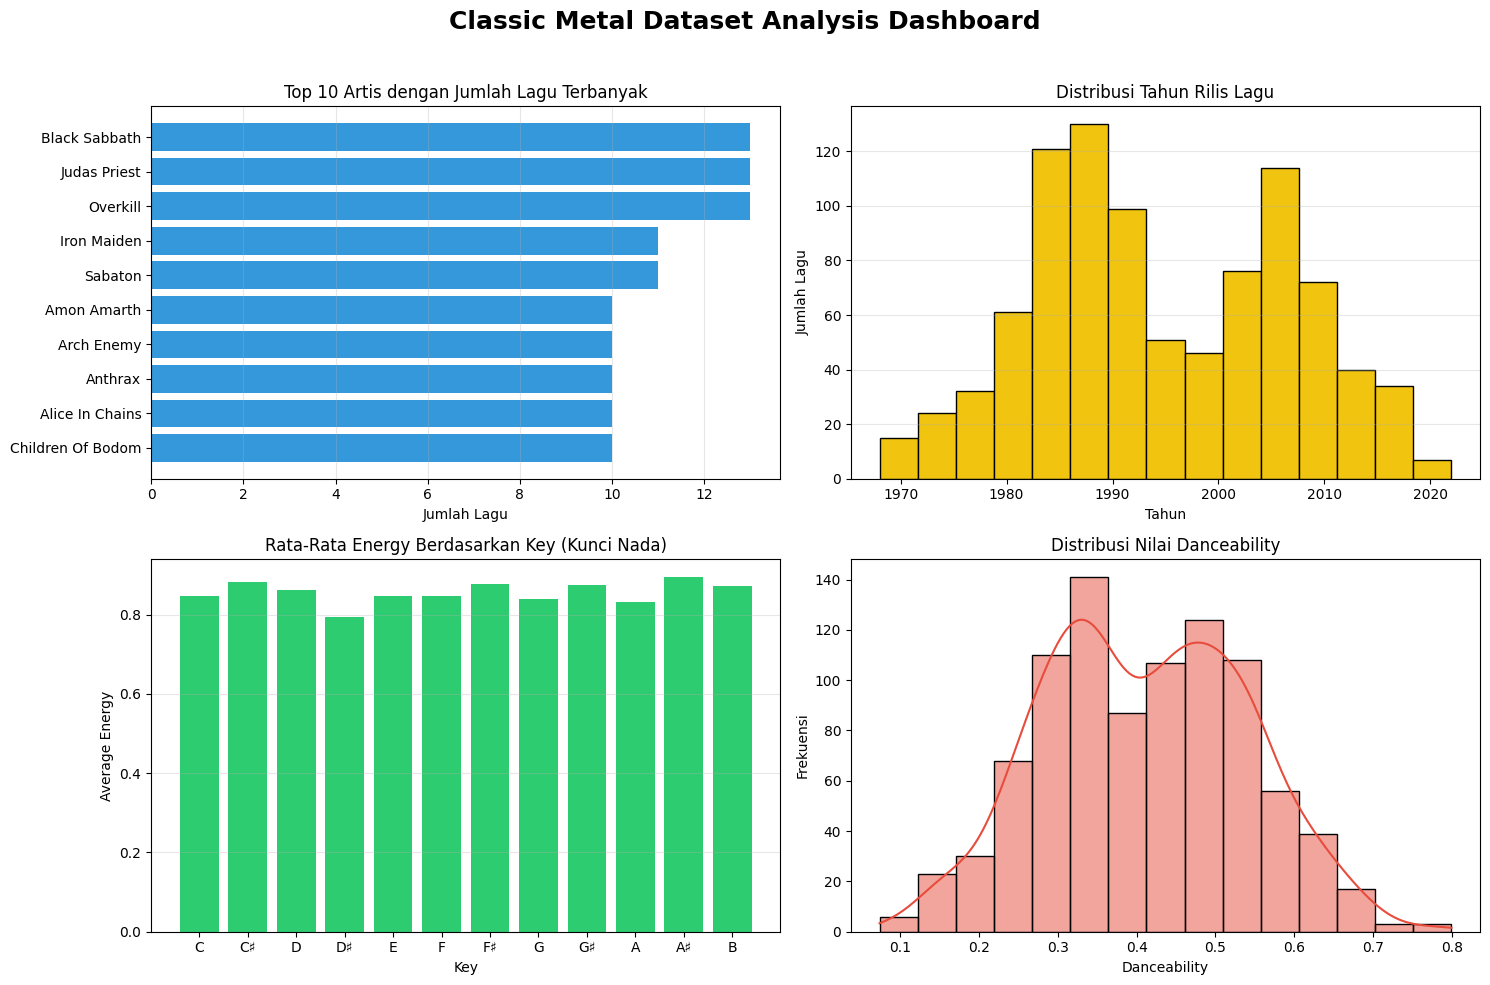


12. PREPROCESSING
Baris sebelum : 922
Baris sesudah : 922 (duplikat dibuang: 0)
Missing value pada kolom analisis: 0
Fitur yang dipakai: ['Danceability', 'Valence', 'Tempo', 'Acousticness', 'Speechiness', 'Instrumentalness', 'Liveness', 'Loudness', 'Duration_Min', 'Year', 'Key', 'Mode']


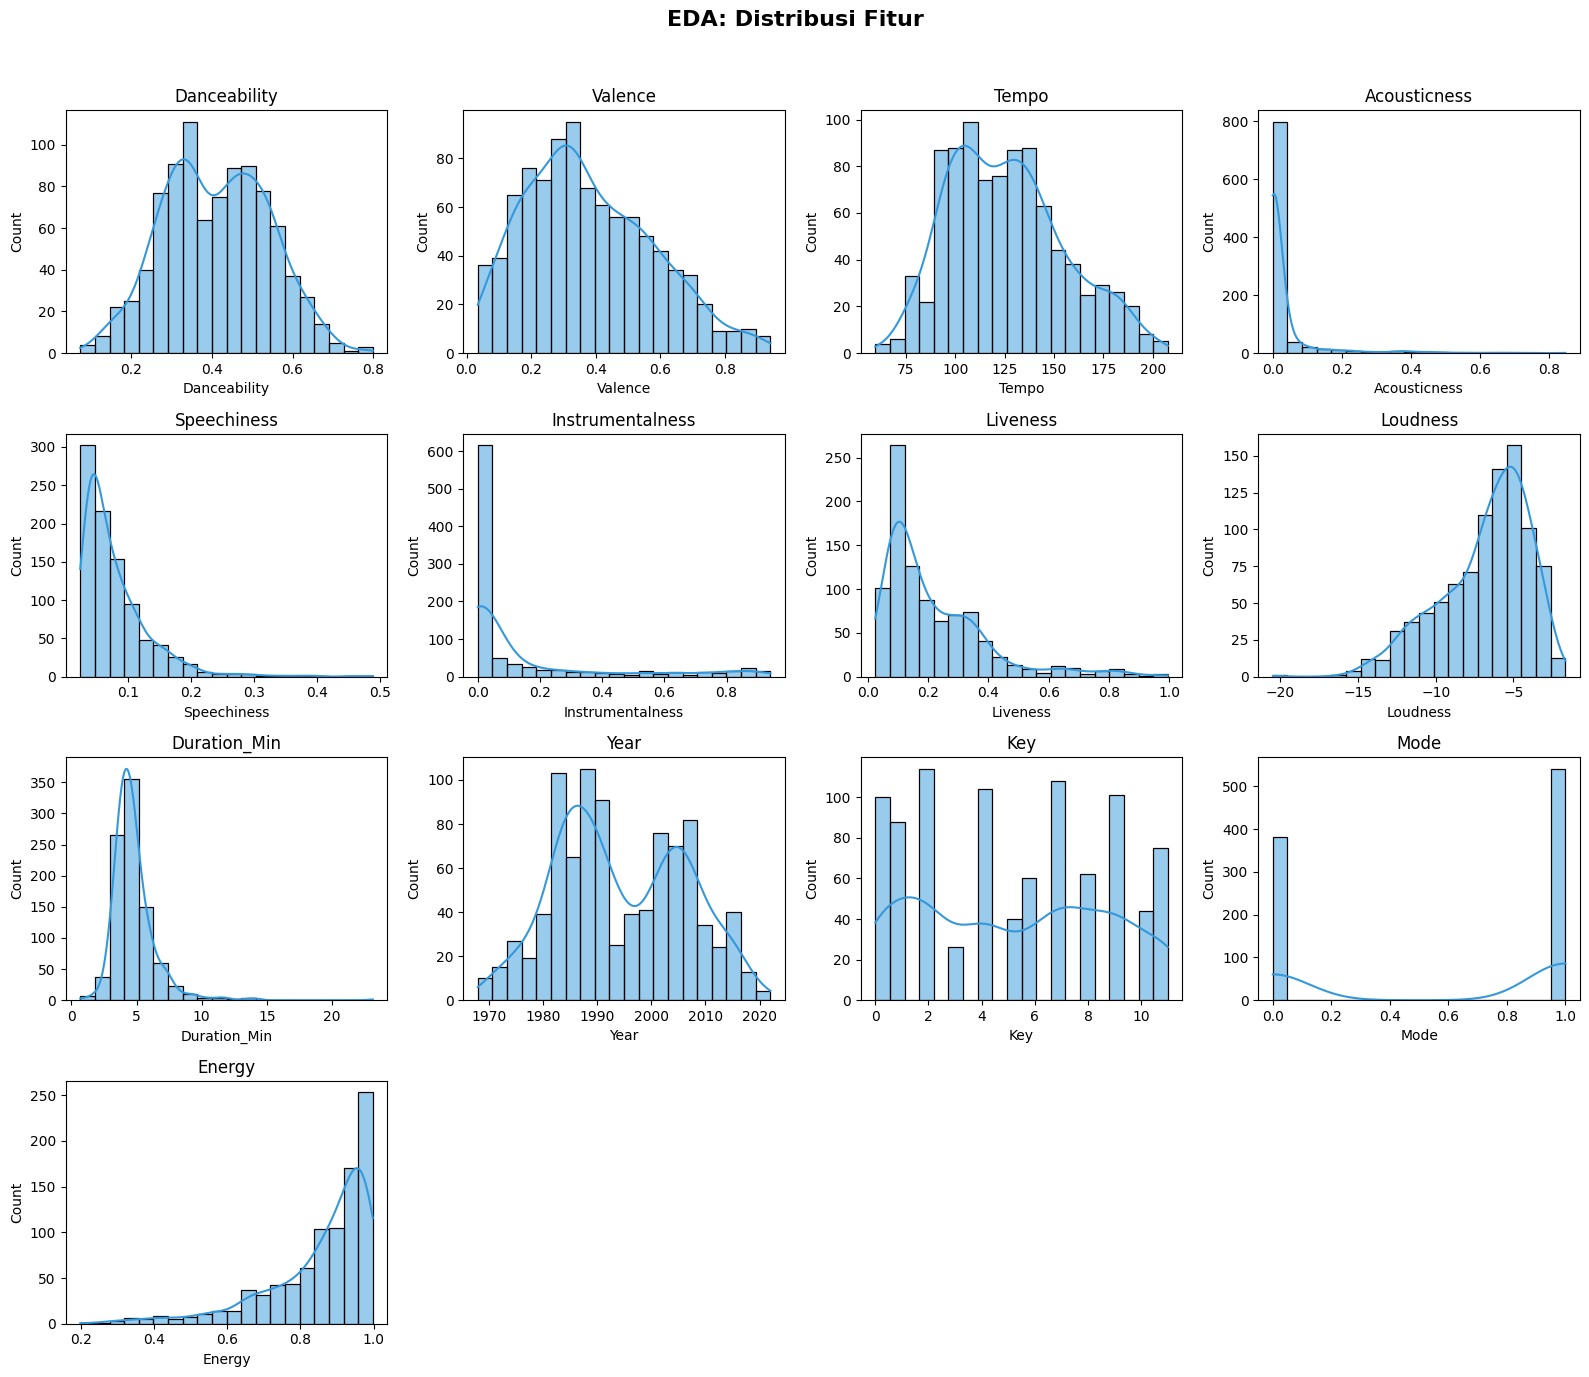

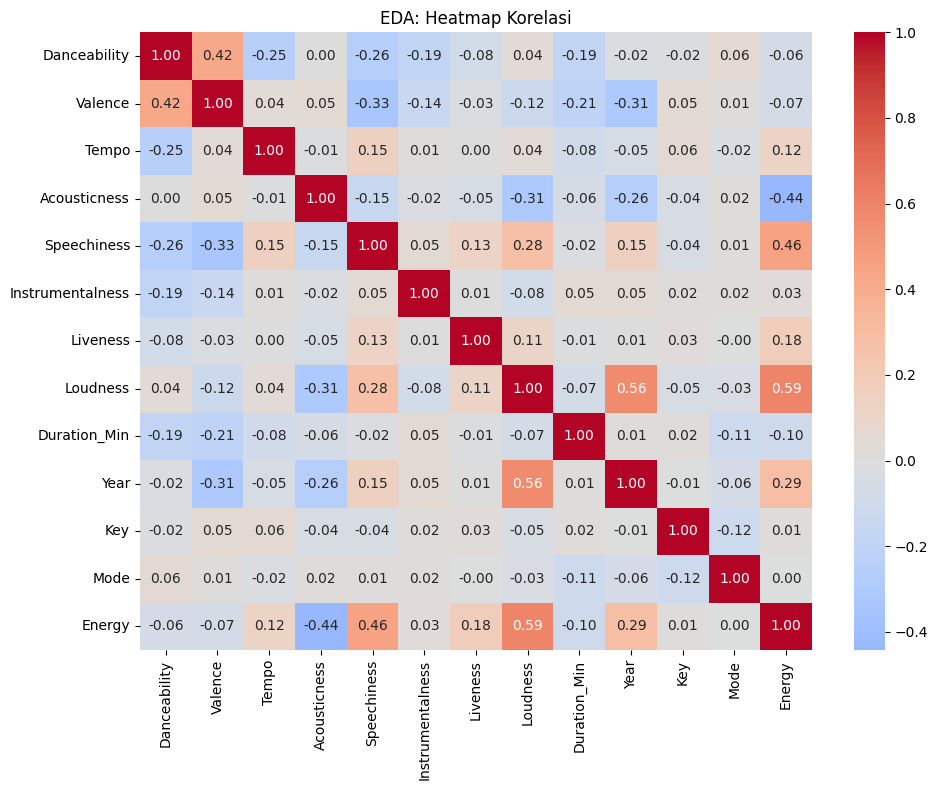


14. FORECASTING JUMLAH LAGU PER TAHUN
MAE data uji (tren linear): 21.43 lagu/tahun
Kemiringan tren: -0.037 lagu per tahun
 Tahun  Prediksi_Jumlah_Lagu
  2023                  15.7
  2024                  15.7
  2025                  15.7
  2026                  15.6
  2027                  15.6

Penjelasan:
Tren linear sederhana dipakai sebagai baseline. Hasilnya hanya indikasi kasar karena data berasal dari satu koleksi lagu, bukan seluruh rilisan metal.


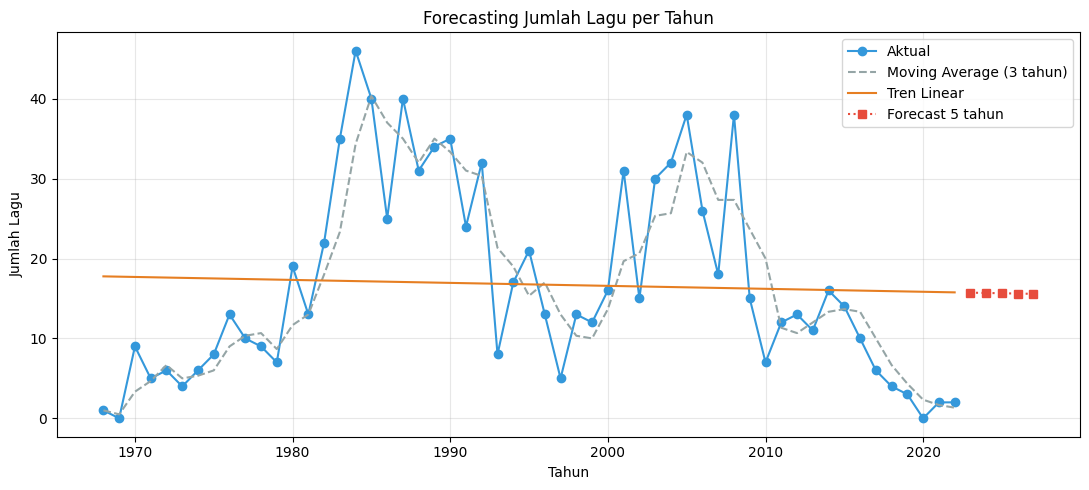


15. ANALISIS SKEWNESS


,Fitur,Skewness,Kurtosis,p-value Normaltest,Kategori
0,Danceability,0.062,-0.539,2.37e-05,Normal (simetris)
1,Valence,0.488,-0.358,1.71e-09,Normal (simetris)
2,Tempo,0.433,-0.394,1.80e-08,Normal (simetris)
3,Acousticness,4.641,25.070,1.77e-194,Tidak normal (sangat miring)
4,Speechiness,2.512,10.119,4.10e-116,Tidak normal (sangat miring)
5,Instrumentalness,1.930,2.402,4.92e-71,Tidak normal (sangat miring)
6,Liveness,1.769,3.467,1.44e-70,Tidak normal (sangat miring)
7,Loudness,-0.841,0.334,5.09e-20,Moderat
8,Duration_Min,3.020,20.771,2.23e-147,Tidak normal (sangat miring)
9,Year,0.120,-0.935,6.12e-32,Normal (simetris)



Penjelasan:
|skew| < 0.5 = simetris, 0.5-1 = moderat, > 1 = sangat miring. p-value Normaltest < 0.05 berarti distribusi berbeda signifikan dari normal.

16. Z-SCORE (|z| > 3)
Danceability         1
Acousticness        29
Speechiness         17
Instrumentalness    11
Liveness            24
Loudness             2
Duration_Min        14
Energy              21
dtype: int64

Baris yang memiliki minimal satu outlier: 104 (11.3%)


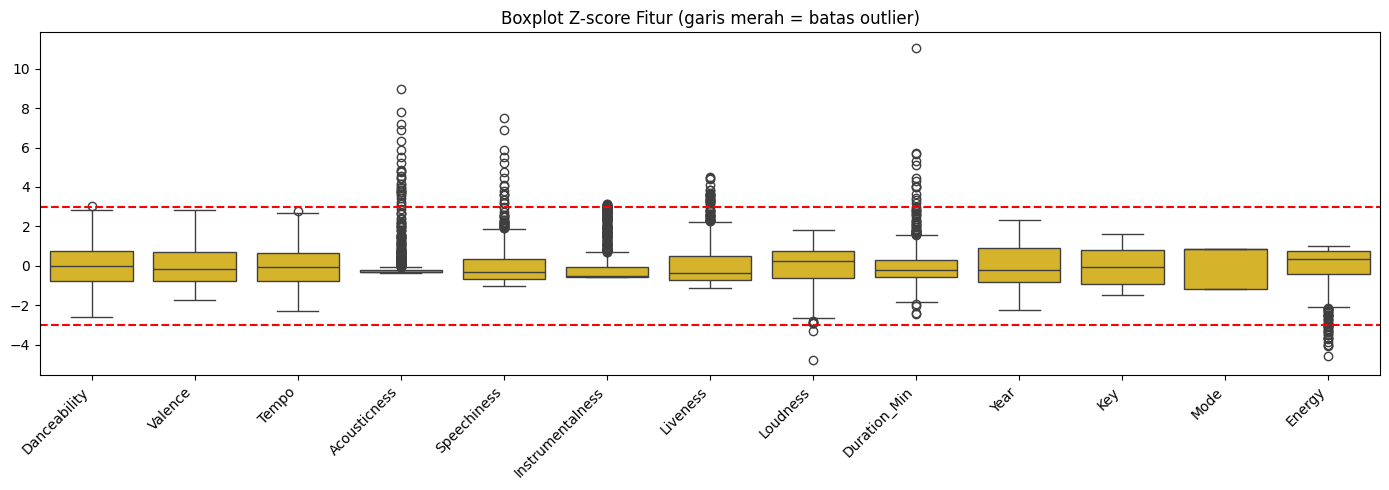


17. HANDLING OUTLIER (CAPPING IQR)


,Outlier_Z_Sebelum,Outlier_Z_Sesudah,Skew_Sebelum,Skew_Sesudah
Danceability,1,0,0.062,0.061
Valence,0,0,0.488,0.488
Tempo,0,0,0.433,0.432
Acousticness,29,0,4.641,1.169
Speechiness,17,0,2.512,1.067
Instrumentalness,11,0,1.930,1.194
Liveness,24,0,1.769,1.164
Loudness,2,0,-0.841,-0.745
Duration_Min,14,0,3.020,0.575
Year,0,0,0.120,0.120



Penjelasan:
Nilai ekstrem dibatasi ke batas IQR (capping), bukan dibuang, sehingga jumlah data tetap sama.

18. UNDERFIT vs OVERFIT (DECISION TREE)
Distribusi target: {0: 461, 1: 461}
 max_depth  Train_Acc  Test_Acc   Gap
         1      0.783     0.762 0.021
         2      0.783     0.762 0.021
         3      0.814     0.795 0.020
         4      0.844     0.800 0.044
         5      0.878     0.822 0.056
         6      0.901     0.832 0.069
         7      0.921     0.832 0.089
         8      0.947     0.827 0.120
         9      0.969     0.816 0.153
        10      0.980     0.816 0.163
        11      0.986     0.795 0.192
        12      0.995     0.773 0.222
        13      0.999     0.795 0.204
        14      1.000     0.795 0.205
        15      1.000     0.795 0.205

Kedalaman terbaik (akurasi uji tertinggi): 6

Penjelasan:
Underfit: akurasi train dan test sama-sama rendah (model terlalu sederhana, depth kecil). Overfit: akurasi train jauh di atas test (gap besar, depth

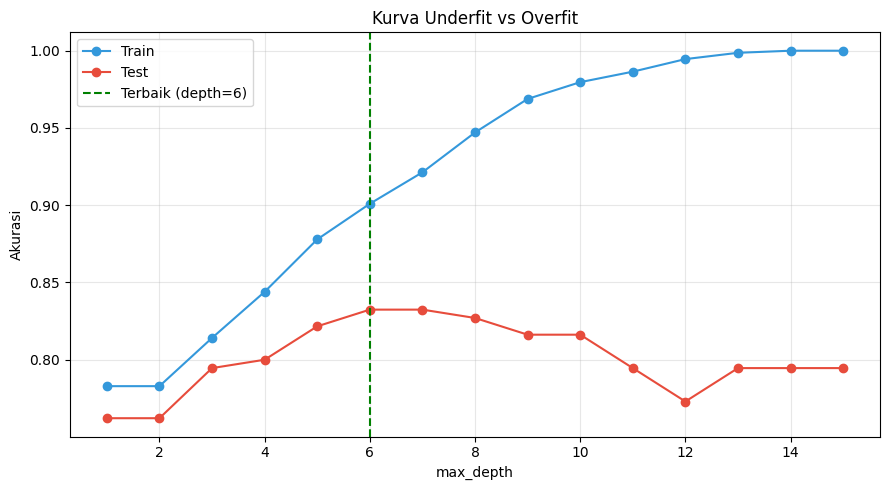


19. MODEL INFERENCE
Prediksi pada 5 lagu data uji:


,Track,Aktual,Prediksi,Prob_High
0,Belly Of The Beast,High,High,0.95
1,Land of Confusion,High,High,0.96
2,Where Eagles Dare,High,High,0.57
3,Wrong Side of Heaven,High,High,0.82
4,Angels Don't Kill - Live in London,Low,High,0.59



Prediksi pada lagu hipotetis (profil fitur persentil 10 dan 90):


,Prediksi,Prob_High
Profil rendah (P10),Low,0.19
Profil tinggi (P90),High,0.74



20. VALIDASI MODEL (RANDOM FOREST BASELINE)
Accuracy  : 0.843
Precision : 0.825
Recall    : 0.870
F1-Score  : 0.847

CV 5-fold F1: 0.795 (+/- 0.021)

Classification Report:
              precision    recall  f1-score   support

  Low Energy       0.86      0.82      0.84        93
 High Energy       0.82      0.87      0.85        92

    accuracy                           0.84       185
   macro avg       0.84      0.84      0.84       185
weighted avg       0.84      0.84      0.84       185

Penjelasan:
Precision = ketepatan prediksi High Energy. Recall = seberapa banyak lagu High Energy yang berhasil ditemukan. F1 = rata-rata harmonik keduanya.


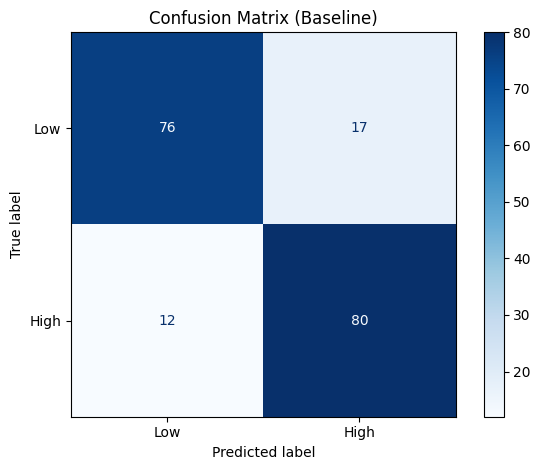


21. TUNING HYPERPARAMETER
Parameter terbaik : {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}
Best CV F1        : 0.806


,Baseline,Tuned,Selisih
Accuracy,0.843,0.832,-0.011
Precision,0.825,0.814,-0.011
Recall,0.870,0.859,-0.011
F1-Score,0.847,0.836,-0.011


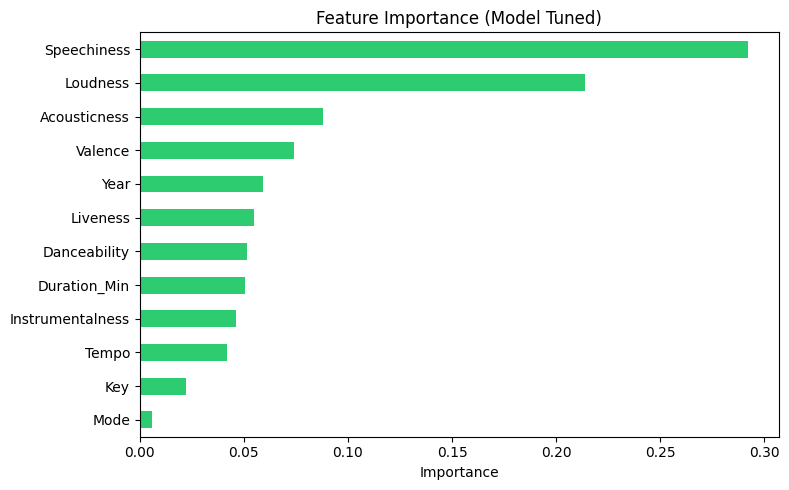


22. RINGKASAN AKHIR


,Tahap,Hasil
0,Preprocessing,"922 baris, 12 fitur"
1,Forecasting,"Tren -0.04 lagu/tahun, MAE 21.43"
2,Skewness,7 dari 13 fitur tidak simetris
3,Z-score,104 baris mengandung outlier
4,Handling Outlier,Capping IQR
5,Underfit/Overfit,Depth terbaik = 6
6,Model Terbaik,"RF tuned, F1 = 0.836"


In [3]:
# ============================================================
# 1. SETUP / IMPORT LIBRARY
# ============================================================
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

try:
    display  # tersedia di Jupyter
except NameError:
    display = print


# ============================================================
# 2. LOADING DATA
# ============================================================
df = pd.read_csv("ClassicMetal.csv")
df.columns = df.columns.str.strip()

print("=" * 70)
print("LOADING DATA")
print("=" * 70)
print("File berhasil dibaca: ClassicMetal.csv")
print("\n5 DATA PERTAMA:")
print(df.head())
print(f"\nTotal Data  : {df.shape[0]} baris")
print(f"Total Kolom : {df.shape[1]} kolom")
print(
    f"\nPenjelasan:\nDataset memiliki {df.shape[0]} baris lagu dan "
    f"{df.shape[1]} kolom atribut musik yang digunakan untuk analisis."
)


# ============================================================
# 3. NAMA KOLOM
# ============================================================
print("\n" + "=" * 70)
print("NAMA KOLOM")
print("=" * 70)
print(df.columns.tolist())


# ============================================================
# 4. INFORMASI TIPE DATA
# ============================================================
print("\n" + "=" * 70)
print("INFORMASI DATA")
print("=" * 70)
df.info()


# ============================================================
# 5. CEK MISSING VALUE
# ============================================================
missing = df.isnull().sum()
total_missing = missing.sum()

print("\n" + "=" * 70)
print("CEK MISSING VALUE")
print("=" * 70)
print(missing)
print("\nPenjelasan:")
if total_missing == 0:
    print("Tidak terdapat missing value pada dataset. Seluruh data lengkap.")
else:
    print(f"Terdapat {total_missing} missing value yang perlu ditangani.")


# ============================================================
# 6. CEK DATA DUPLIKAT
# ============================================================
duplicate_count = df.duplicated().sum()

print("\n" + "=" * 70)
print("CEK DATA DUPLIKAT")
print("=" * 70)
print(f"Jumlah baris duplikat: {duplicate_count}")
print("\nPenjelasan:")
if duplicate_count == 0:
    print("Tidak ditemukan baris duplikat dalam dataset.")
else:
    print(f"Ditemukan {duplicate_count} baris duplikat yang perlu diperiksa.")


# ============================================================
# 7. REKAYASA FITUR
# ============================================================
if "Duration" in df.columns:
    df["Duration_Min"] = df["Duration"] / 60000  # ms -> menit

key_mapping = {
    -1: "Tidak Terdeteksi",
    0: "C", 1: "C♯ / D♭", 2: "D", 3: "D♯ / E♭",
    4: "E", 5: "F", 6: "F♯ / G♭", 7: "G",
    8: "G♯ / A♭", 9: "A", 10: "A♯ / B♭", 11: "B",
}
df["Key_Name"] = df["Key"].map(key_mapping)

print("\n" + "=" * 70)
print("REKAYASA FITUR")
print("=" * 70)
cols_show = [c for c in ["Track", "Artist", "Duration", "Duration_Min", "Key", "Key_Name"] if c in df.columns]
print(df[cols_show].head().round(2))


# ============================================================
# 8. STATISTIK DESKRIPTIF
# ============================================================
print("\n" + "=" * 70)
print("STATISTIK DESKRIPTIF")
print("=" * 70)
print(df.describe().round(2))


# ============================================================
# 9. MENYIMPAN DATA BERSIH
# ============================================================
df.to_csv("classic_metal_clean.csv", index=False)

print("\n" + "=" * 70)
print("DATA CLEAN BERHASIL DISIMPAN")
print("=" * 70)
print("File: classic_metal_clean.csv")


# ============================================================
# Q1: TOP 10 ARTIS DENGAN LAGU TERBANYAK
# ============================================================
top_artists = df["Artist"].value_counts().head(10)
top_artist_name = top_artists.index[0]
top_artist_count = top_artists.iloc[0]

print("\n" + "=" * 70)
print("Q1. TOP 10 ARTIS DENGAN JUMLAH LAGU TERBANYAK")
print("=" * 70)
print(top_artists)
print(f"\nPenjelasan:\nArtis dengan lagu terbanyak adalah {top_artist_name} "
      f"dengan total {top_artist_count} lagu.")


# ============================================================
# Q2: RATA-RATA DANCEABILITY & ENERGY PER ARTIS (MIN. 5 LAGU)
# ============================================================
artist_stats = (
    df.groupby("Artist")
    .agg(
        Total_Tracks=("Track", "count"),
        Avg_Danceability=("Danceability", "mean"),
        Avg_Energy=("Energy", "mean"),
    )
    .query("Total_Tracks >= 5")
    .sort_values("Avg_Energy", ascending=False)
)

print("\n" + "=" * 70)
print("Q2. RATA-RATA DANCEABILITY & ENERGY PER ARTIS (MIN 5 LAGU)")
print("=" * 70)

if artist_stats.empty:
    most_energetic_artist = "Tidak ada (tidak ada artis dengan >= 5 lagu)"
    print(most_energetic_artist)
else:
    print(artist_stats.head(10).round(2))
    most_energetic_artist = artist_stats.index[0]
    print(f"\nPenjelasan:\nArtis paling energik (minimal 5 lagu) adalah "
          f"{most_energetic_artist} dengan rata-rata Energy "
          f"{artist_stats.iloc[0]['Avg_Energy']:.2f}.")


# ============================================================
# Q3: LAGU PALING ENERGIK & PALING DANCEABLE
# ============================================================
top_energy_track = df.loc[df["Energy"].idxmax()]
top_dance_track = df.loc[df["Danceability"].idxmax()]

print("\n" + "=" * 70)
print("Q3. LAGU TERATAS BERDASARKAN METRIK")
print("=" * 70)
print(f"Lagu Paling Energik   : {top_energy_track['Track']} - "
      f"{top_energy_track['Artist']} (Energy: {top_energy_track['Energy']})")
print(f"Lagu Paling Danceable : {top_dance_track['Track']} - "
      f"{top_dance_track['Artist']} (Danceability: {top_dance_track['Danceability']})")

lagu_menari = df.sort_values(
    by=["Danceability", "Energy"],
    ascending=False
)

print(
    lagu_menari[
        ["Track", "Artist", "Danceability", "Energy"]
    ].head(10)
)

# ============================================================
# Q4: DISTRIBUSI KEY
# ============================================================
key_dist = df["Key"].value_counts().sort_index()
key_dist_valid = df.loc[df["Key"] != -1, "Key"].value_counts()  # abaikan "tidak terdeteksi"

most_common_key = key_dist_valid.idxmax()
most_common_key_name = key_mapping.get(most_common_key, "Unknown")

print("\n" + "=" * 70)
print("Q4. DISTRIBUSI KUNCI NADA (KEY)")
print("=" * 70)
print(key_dist.rename(index=key_mapping))
print(f"\nPenjelasan:\nKunci nada yang paling sering digunakan adalah Key "
      f"{most_common_key} ({most_common_key_name}) dengan total "
      f"{key_dist_valid.max()} lagu.")


# ============================================================
# Q5: TAHUN RILIS TERBANYAK
# ============================================================
tracks_per_year = df["Year"].value_counts().sort_index()
top_year = tracks_per_year.idxmax()
top_year_count = tracks_per_year.max()

print("\n" + "=" * 70)
print("Q5. TAHUN PRODUKTIF RILIS LAGU")
print("=" * 70)
print(f"Tahun dengan rilis lagu terbanyak: {top_year} ({top_year_count} lagu)")


# ============================================================
# FUNGSI BANTU: INTERPRETASI KORELASI
# ============================================================
def interpretasi(r, p, a, b):
    if p >= 0.05:
        return f"Tidak ada hubungan yang signifikan secara statistik antara {a} dan {b}."
    kekuatan = abs(r)
    if kekuatan < 0.3:
        level = "lemah"
    elif kekuatan < 0.7:
        level = "sedang"
    else:
        level = "kuat"
    arah = "positif" if r > 0 else "negatif"
    return (f"Terdapat hubungan {arah} yang {level} dan signifikan antara {a} dan {b} "
            f"(r = {r:.3f}).")


# ============================================================
# Q6: PEARSON ENERGY vs LOUDNESS
# ============================================================
d6 = df[["Energy", "Loudness"]].dropna()
corr_el, pval_el = stats.pearsonr(d6["Energy"], d6["Loudness"])

print("\n" + "=" * 70)
print("Q6. UJI KORELASI PEARSON (ENERGY VS LOUDNESS)")
print("=" * 70)
print(f"Correlation (r) : {corr_el:.3f}")
print(f"P-value         : {pval_el:.2e}")
print("\nPenjelasan:")
print(interpretasi(corr_el, pval_el, "Energy", "Loudness"))


# ============================================================
# Q7: PEARSON DANCEABILITY vs ENERGY
# ============================================================
d7 = df[["Danceability", "Energy"]].dropna()
corr_de, pval_de = stats.pearsonr(d7["Danceability"], d7["Energy"])

print("\n" + "=" * 70)
print("Q7. UJI KORELASI PEARSON (DANCEABILITY VS ENERGY)")
print("=" * 70)
print(f"Correlation (r) : {corr_de:.3f}")
print(f"P-value         : {pval_de:.2e}")
print("\nPenjelasan:")
print(interpretasi(corr_de, pval_de, "Danceability", "Energy"))


# ============================================================
# 10. TABEL RINGKASAN HASIL ANALISIS (SETELAH SEMUA VARIABEL ADA)
# ============================================================
summary_table = pd.DataFrame({
    "No": range(1, 8),
    "Analisis": [
        "Top Artist",
        "Artis Paling Energik",
        "Lagu Paling Energik",
        "Key Paling Populer",
        "Tahun Rilis Terbanyak",
        "Korelasi Energy vs Loudness",
        "Korelasi Danceability vs Energy",
    ],
    "Hasil Utama": [
        f"{top_artist_name} ({top_artist_count} lagu)",
        f"{most_energetic_artist}",
        f"{top_energy_track['Track']} ({top_energy_track['Artist']})",
        f"Key {most_common_key} ({most_common_key_name})",
        f"Tahun {top_year} ({top_year_count} lagu)",
        f"r = {corr_el:.3f} (p = {pval_el:.2e})",
        f"r = {corr_de:.3f} (p = {pval_de:.2e})",
    ],
})

print("\n" + "=" * 70)
print("TABEL RINGKASAN HASIL ANALISIS")
print("=" * 70)
display(summary_table)


# ============================================================
# 11. DASHBOARD VISUALISASI
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Classic Metal Dataset Analysis Dashboard", fontsize=18, fontweight="bold")

# 1. Top 10 artis
axes[0, 0].barh(top_artists.index[::-1], top_artists.values[::-1], color="#3498db")
axes[0, 0].set_title("Top 10 Artis dengan Jumlah Lagu Terbanyak")
axes[0, 0].set_xlabel("Jumlah Lagu")
axes[0, 0].grid(axis="x", alpha=0.3)

# 2. Distribusi tahun
axes[0, 1].hist(df["Year"].dropna(), bins=15, color="#f1c40f", edgecolor="black")
axes[0, 1].set_title("Distribusi Tahun Rilis Lagu")
axes[0, 1].set_xlabel("Tahun")
axes[0, 1].set_ylabel("Jumlah Lagu")
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Rata-rata Energy per Key (dengan nama nada)
avg_energy_key = df[df["Key"] != -1].groupby("Key")["Energy"].mean()
labels = [key_mapping[k].split(" / ")[0] for k in avg_energy_key.index]
axes[1, 0].bar(labels, avg_energy_key.values, color="#2ecc71")
axes[1, 0].set_title("Rata-Rata Energy Berdasarkan Key (Kunci Nada)")
axes[1, 0].set_xlabel("Key")
axes[1, 0].set_ylabel("Average Energy")
axes[1, 0].grid(axis="y", alpha=0.3)

# 4. Distribusi Danceability
sns.histplot(df["Danceability"].dropna(), kde=True, ax=axes[1, 1], color="#e74c3c", bins=15)
axes[1, 1].set_title("Distribusi Nilai Danceability")
axes[1, 1].set_xlabel("Danceability")
axes[1, 1].set_ylabel("Frekuensi")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("metal_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()




# ============================================================
# LANJUTAN: tempel SETELAH bagian "11. DASHBOARD VISUALISASI"
# Butuh variabel dari kode sebelumnya: df, key_mapping, display
#
# Alur: 12 Preprocessing -> 13 EDA -> 14 Forecasting -> 15 Skewness
#       -> 16 Z-score -> 17 Handling Outlier -> 18 Underfit
#       -> 19 Model Inference -> 20 Validasi (F1/Recall/Precision)
#       -> 21 Tuning -> 22 Ringkasan
# ============================================================
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

# Fitur numerik kandidat (hanya yang ada di dataset yang dipakai)
CANDIDATE_FEATURES = [
    "Danceability", "Valence", "Tempo", "Acousticness", "Speechiness",
    "Instrumentalness", "Liveness", "Loudness", "Duration_Min", "Year", "Key", "Mode",
]
feats = [c for c in CANDIDATE_FEATURES if c in df.columns]
analysis_cols = feats + ["Energy"]


# ============================================================
# 12. PREPROCESSING
# ============================================================
df_pre = df.copy()

n_before = len(df_pre)
df_pre = df_pre.drop_duplicates().reset_index(drop=True)

for c in analysis_cols:
    df_pre[c] = pd.to_numeric(df_pre[c], errors="coerce")
    df_pre[c] = df_pre[c].fillna(df_pre[c].median())

print("\n" + "=" * 70)
print("12. PREPROCESSING")
print("=" * 70)
print(f"Baris sebelum : {n_before}")
print(f"Baris sesudah : {len(df_pre)} (duplikat dibuang: {n_before - len(df_pre)})")
print(f"Missing value pada kolom analisis: {df_pre[analysis_cols].isnull().sum().sum()}")
print(f"Fitur yang dipakai: {feats}")


# ============================================================
# 13. GRAFIK EDA
# ============================================================
n = len(analysis_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.5 * nrows))
axes = np.array(axes).ravel()
for ax, col in zip(axes, analysis_cols):
    sns.histplot(df_pre[col], kde=True, ax=ax, color="#3498db", bins=20)
    ax.set_title(col)
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("EDA: Distribusi Fitur", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("eda_distribusi.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df_pre[analysis_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("EDA: Heatmap Korelasi")
plt.tight_layout()
plt.savefig("eda_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 14. FORECASTING (JUMLAH LAGU PER TAHUN, TREN LINEAR)
# ============================================================
yearly = df_pre["Year"].astype(int).value_counts().sort_index()
yearly = yearly.reindex(range(yearly.index.min(), yearly.index.max() + 1), fill_value=0)

years = yearly.index.values
counts = yearly.values

# Evaluasi: latih di 80% tahun awal, uji di 20% tahun akhir
split = max(int(len(years) * 0.8), 2)
coef_tr = np.polyfit(years[:split], counts[:split], deg=1)
pred_test = np.polyval(coef_tr, years[split:])
mae = np.mean(np.abs(pred_test - counts[split:])) if len(pred_test) else np.nan

# Latih ulang di semua data lalu prediksi 5 tahun ke depan
coef_all = np.polyfit(years, counts, deg=1)
future_years = np.arange(years.max() + 1, years.max() + 6)
future_pred = np.clip(np.polyval(coef_all, future_years), 0, None)
ma3 = pd.Series(counts, index=years).rolling(3, min_periods=1).mean()

print("\n" + "=" * 70)
print("14. FORECASTING JUMLAH LAGU PER TAHUN")
print("=" * 70)
print(f"MAE data uji (tren linear): {mae:.2f} lagu/tahun")
print(f"Kemiringan tren: {coef_all[0]:+.3f} lagu per tahun")
print(pd.DataFrame({"Tahun": future_years, "Prediksi_Jumlah_Lagu": future_pred.round(1)}).to_string(index=False))
print("\nPenjelasan:")
print("Tren linear sederhana dipakai sebagai baseline. Hasilnya hanya indikasi kasar "
      "karena data berasal dari satu koleksi lagu, bukan seluruh rilisan metal.")

plt.figure(figsize=(11, 5))
plt.plot(years, counts, marker="o", label="Aktual", color="#3498db")
plt.plot(years, ma3, linestyle="--", label="Moving Average (3 tahun)", color="#95a5a6")
plt.plot(years, np.polyval(coef_all, years), label="Tren Linear", color="#e67e22")
plt.plot(future_years, future_pred, marker="s", linestyle=":", label="Forecast 5 tahun", color="#e74c3c")
plt.title("Forecasting Jumlah Lagu per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Lagu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("forecasting.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 15. ANALISIS SKEWNESS (NORMAL / MODERAT / TIDAK NORMAL)
# ============================================================
def kategori_skew(s):
    a = abs(s)
    if a < 0.5:
        return "Normal (simetris)"
    elif a < 1:
        return "Moderat"
    return "Tidak normal (sangat miring)"


skew_rows = []
for c in analysis_cols:
    s = stats.skew(df_pre[c])
    k = stats.kurtosis(df_pre[c])
    p = stats.normaltest(df_pre[c])[1] if len(df_pre) >= 8 else np.nan
    skew_rows.append({
        "Fitur": c, "Skewness": round(s, 3), "Kurtosis": round(k, 3),
        "p-value Normaltest": f"{p:.2e}", "Kategori": kategori_skew(s),
    })
skew_table = pd.DataFrame(skew_rows)

print("\n" + "=" * 70)
print("15. ANALISIS SKEWNESS")
print("=" * 70)
display(skew_table)
print("\nPenjelasan:")
print("|skew| < 0.5 = simetris, 0.5-1 = moderat, > 1 = sangat miring. "
      "p-value Normaltest < 0.05 berarti distribusi berbeda signifikan dari normal.")


# ============================================================
# 16. Z-SCORE (DETEKSI OUTLIER)
# ============================================================
z = pd.DataFrame(stats.zscore(df_pre[analysis_cols]), columns=analysis_cols)
outlier_z = (z.abs() > 3).sum()
rows_with_outlier = (z.abs() > 3).any(axis=1).sum()

print("\n" + "=" * 70)
print("16. Z-SCORE (|z| > 3)")
print("=" * 70)
print(outlier_z[outlier_z > 0] if (outlier_z > 0).any() else "Tidak ada outlier berdasarkan Z-score.")
print(f"\nBaris yang memiliki minimal satu outlier: {rows_with_outlier} "
      f"({rows_with_outlier / len(df_pre) * 100:.1f}%)")

plt.figure(figsize=(14, 5))
sns.boxplot(data=z, orient="v", color="#f1c40f")
plt.axhline(3, color="red", linestyle="--")
plt.axhline(-3, color="red", linestyle="--")
plt.xticks(rotation=45, ha="right")
plt.title("Boxplot Z-score Fitur (garis merah = batas outlier)")
plt.tight_layout()
plt.savefig("zscore_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 17. HANDLING OUTLIER (CAPPING METODE IQR)
# ============================================================
df_out = df_pre.copy()
for c in analysis_cols:
    q1, q3 = df_out[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    df_out[c] = df_out[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

z_after = pd.DataFrame(stats.zscore(df_out[analysis_cols]), columns=analysis_cols)
cmp = pd.DataFrame({
    "Outlier_Z_Sebelum": outlier_z,
    "Outlier_Z_Sesudah": (z_after.abs() > 3).sum(),
    "Skew_Sebelum": [round(stats.skew(df_pre[c]), 3) for c in analysis_cols],
    "Skew_Sesudah": [round(stats.skew(df_out[c]), 3) for c in analysis_cols],
})

print("\n" + "=" * 70)
print("17. HANDLING OUTLIER (CAPPING IQR)")
print("=" * 70)
display(cmp)
print("\nPenjelasan:")
print("Nilai ekstrem dibatasi ke batas IQR (capping), bukan dibuang, "
      "sehingga jumlah data tetap sama.")


# ============================================================
# 18. DETEKSI UNDERFIT vs OVERFIT
# Target: High_Energy = 1 jika Energy >= median
# ============================================================
df_out["High_Energy"] = (df_out["Energy"] >= df_out["Energy"].median()).astype(int)
model_feats = feats  # Energy sengaja tidak dipakai agar tidak bocor ke target

X = df_out[model_feats]
y = df_out["High_Energy"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

depths = range(1, 16)
fit_rows = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    fit_rows.append({
        "max_depth": d,
        "Train_Acc": accuracy_score(y_train, m.predict(X_train)),
        "Test_Acc": accuracy_score(y_test, m.predict(X_test)),
    })
fit_df = pd.DataFrame(fit_rows)
fit_df["Gap"] = fit_df["Train_Acc"] - fit_df["Test_Acc"]
best_depth = int(fit_df.loc[fit_df["Test_Acc"].idxmax(), "max_depth"])

print("\n" + "=" * 70)
print("18. UNDERFIT vs OVERFIT (DECISION TREE)")
print("=" * 70)
print(f"Distribusi target: {y.value_counts().to_dict()}")
print(fit_df.round(3).to_string(index=False))
print(f"\nKedalaman terbaik (akurasi uji tertinggi): {best_depth}")
print("\nPenjelasan:")
print("Underfit: akurasi train dan test sama-sama rendah (model terlalu sederhana, depth kecil). "
      "Overfit: akurasi train jauh di atas test (gap besar, depth besar).")

plt.figure(figsize=(9, 5))
plt.plot(fit_df["max_depth"], fit_df["Train_Acc"], marker="o", label="Train", color="#3498db")
plt.plot(fit_df["max_depth"], fit_df["Test_Acc"], marker="o", label="Test", color="#e74c3c")
plt.axvline(best_depth, color="green", linestyle="--", label=f"Terbaik (depth={best_depth})")
plt.title("Kurva Underfit vs Overfit")
plt.xlabel("max_depth")
plt.ylabel("Akurasi")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("underfit_overfit.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 19. MODEL INFERENCE (PREDIKSI LAGU BARU)
# ============================================================
model_base = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE).fit(X_train, y_train)

sample = X_test.sample(min(5, len(X_test)), random_state=RANDOM_STATE)
infer = pd.DataFrame({
    "Track": df_out.loc[sample.index, "Track"].values if "Track" in df_out.columns else sample.index,
    "Aktual": y_test.loc[sample.index].map({0: "Low", 1: "High"}).values,
    "Prediksi": pd.Series(model_base.predict(sample)).map({0: "Low", 1: "High"}).values,
    "Prob_High": model_base.predict_proba(sample)[:, 1].round(3),
})

profil = pd.DataFrame([X_train.quantile(0.10), X_train.quantile(0.90)], index=["Profil rendah (P10)", "Profil tinggi (P90)"])
profil_pred = pd.DataFrame({
    "Prediksi": pd.Series(model_base.predict(profil), index=profil.index).map({0: "Low", 1: "High"}),
    "Prob_High": model_base.predict_proba(profil)[:, 1].round(3),
})

print("\n" + "=" * 70)
print("19. MODEL INFERENCE")
print("=" * 70)
print("Prediksi pada 5 lagu data uji:")
display(infer)
print("\nPrediksi pada lagu hipotetis (profil fitur persentil 10 dan 90):")
display(profil_pred)


# ============================================================
# 20. VALIDASI MODEL (ACCURACY, PRECISION, RECALL, F1)
# ============================================================
y_pred = model_base.predict(X_test)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE), X, y, cv=cv, scoring="f1"
)

base_scores = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
}

print("\n" + "=" * 70)
print("20. VALIDASI MODEL (RANDOM FOREST BASELINE)")
print("=" * 70)
for k, v in base_scores.items():
    print(f"{k:<10}: {v:.3f}")
print(f"\nCV 5-fold F1: {cv_f1.mean():.3f} (+/- {cv_f1.std():.3f})")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Low Energy", "High Energy"]))
print("Penjelasan:")
print("Precision = ketepatan prediksi High Energy. Recall = seberapa banyak lagu High Energy "
      "yang berhasil ditemukan. F1 = rata-rata harmonik keduanya.")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Low", "High"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Baseline)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 21. TUNING HYPERPARAMETER (GRIDSEARCHCV)
# ============================================================
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 8, 15],
    "min_samples_leaf": [1, 3],
}
grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid, cv=cv, scoring="f1", n_jobs=-1,
)
grid.fit(X_train, y_train)
model_tuned = grid.best_estimator_
y_pred_t = model_tuned.predict(X_test)

tuned_scores = {
    "Accuracy": accuracy_score(y_test, y_pred_t),
    "Precision": precision_score(y_test, y_pred_t),
    "Recall": recall_score(y_test, y_pred_t),
    "F1-Score": f1_score(y_test, y_pred_t),
}
compare = pd.DataFrame({"Baseline": base_scores, "Tuned": tuned_scores}).round(3)
compare["Selisih"] = (compare["Tuned"] - compare["Baseline"]).round(3)

print("\n" + "=" * 70)
print("21. TUNING HYPERPARAMETER")
print("=" * 70)
print(f"Parameter terbaik : {grid.best_params_}")
print(f"Best CV F1        : {grid.best_score_:.3f}")
display(compare)

imp = pd.Series(model_tuned.feature_importances_, index=model_feats).sort_values()
plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="#2ecc71")
plt.title("Feature Importance (Model Tuned)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# 22. RINGKASAN AKHIR
# ============================================================
final_summary = pd.DataFrame({
    "Tahap": [
        "Preprocessing", "Forecasting", "Skewness", "Z-score",
        "Handling Outlier", "Underfit/Overfit", "Model Terbaik",
    ],
    "Hasil": [
        f"{len(df_pre)} baris, {len(feats)} fitur",
        f"Tren {coef_all[0]:+.2f} lagu/tahun, MAE {mae:.2f}",
        f"{(skew_table['Kategori'] != 'Normal (simetris)').sum()} dari {len(skew_table)} fitur tidak simetris",
        f"{rows_with_outlier} baris mengandung outlier",
        "Capping IQR",
        f"Depth terbaik = {best_depth}",
        f"RF tuned, F1 = {tuned_scores['F1-Score']:.3f}",
    ],
})

print("\n" + "=" * 70)
print("22. RINGKASAN AKHIR")
print("=" * 70)
display(final_summary)

In [ ]:
# ============================================================
# 1. SETUP / IMPORT LIBRARY
# ============================================================
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

try:
    display  # tersedia di Jupyter
except NameError:
    display = print
# Urutkan lagu berdasarkan Danceability tertinggi
lagu_menari = df.sort_values(
    by=["Danceability", "Energy"],
    ascending=False
)

print(
    lagu_menari[
        ["Track", "Artist", "Danceability", "Energy"]
    ].head(10)
)

In [1]:
# ============================================================
# KODE PENGOLAHAN DATA SIMPEL SIAP TABLEAU
# ============================================================
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# 1. Load Data & Preprocessing Dasar
df = pd.read_csv("ClassicMetal.csv")
df.columns = df.columns.str.strip()
df = df.drop_duplicates().reset_index(drop=True)

# Rekayasa Fitur Dasar
if "Duration" in df.columns:
    df["Duration_Min"] = (df["Duration"] / 60000).round(2)

key_mapping = {
    -1: "Unknown",
    0: "C",
    1: "C#/Db",
    2: "D",
    3: "D#/Eb",
    4: "E",
    5: "F",
    6: "F#/Gb",
    7: "G",
    8: "G#/Ab",
    9: "A",
    10: "A#/Bb",
    11: "B",
}
df["Key_Name"] = df["Key"].map(key_mapping)

# Kolom Fitur Analisis
feats = [
    c
    for c in [
        "Danceability",
        "Valence",
        "Tempo",
        "Acousticness",
        "Speechiness",
        "Instrumentalness",
        "Liveness",
        "Loudness",
        "Duration_Min",
        "Year",
        "Key",
        "Mode",
    ]
    if c in df.columns
]
analysis_cols = feats + ["Energy"]

# Imputasi Missing Value
for c in analysis_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df[c] = df[c].fillna(df[c].median())

# 2. Handling Outlier (Capping IQR) -> Disimpan ke Kolom Khusus
df_clean = df.copy()
for c in analysis_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    # Buat kolom capped agar di Tableau bisa langsung di-plot tanpa outlier liar
    df_clean[f"{c}_Capped"] = df_clean[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Label High Energy untuk Target Modeling
df_clean["High_Energy"] = (
    df_clean["Energy"] >= df_clean["Energy"].median()
).astype(int)

# Ekspor Dataset Utama Siap Tableau
df_clean.to_csv("ClassicMetal_Tableau_Clean.csv", index=False)
print("Saved: ClassicMetal_Tableau_Clean.csv (Dataset Utama)")


# ============================================================
# PREPARASI DATASET FORECASTING & FEATURE IMPORTANCE UNTUK TABLEAU
# ============================================================

# A. Data Forecasting Rilisan Lagu
yearly = df_clean["Year"].astype(int).value_counts().sort_index()
yearly = yearly.reindex(
    range(yearly.index.min(), yearly.index.max() + 1), fill_value=0
)
years = yearly.index.values
counts = yearly.values

coef_all = np.polyfit(years, counts, deg=1)
future_years = np.arange(years.max() + 1, years.max() + 6)
future_pred = np.clip(np.polyval(coef_all, future_years), 0, None)

df_hist = pd.DataFrame(
    {
        "Tahun": years,
        "Jumlah_Lagu": counts,
        "Tipe_Data": "Aktual",
        "Trend_Linear": np.polyval(coef_all, years).round(1),
    }
)

df_fut = pd.DataFrame(
    {
        "Tahun": future_years,
        "Jumlah_Lagu": future_pred.round(1),
        "Tipe_Data": "Forecast",
        "Trend_Linear": future_pred.round(1),
    }
)

df_forecast_tableau = pd.concat([df_hist, df_fut], ignore_index=True)
df_forecast_tableau.to_csv("Tableau_Forecasting.csv", index=False)
print("Saved: Tableau_Forecasting.csv (Data Tren & Forecast)")

# B. Data Feature Importance (Machine Learning)
X = df_clean[feats]
y = df_clean["High_Energy"]
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X, y)

df_imp = pd.DataFrame(
    {"Fitur": feats, "Importance": rf.feature_importances_}
).sort_values(by="Importance", ascending=False)

df_imp.to_csv("Tableau_Feature_Importance.csv", index=False)
print("Saved: Tableau_Feature_Importance.csv (Klasifikasi Fitur)")

Saved: ClassicMetal_Tableau_Clean.csv (Dataset Utama)
Saved: Tableau_Forecasting.csv (Data Tren & Forecast)
Saved: Tableau_Feature_Importance.csv (Klasifikasi Fitur)
